# Notebook for Hw 1

## 1. Read the CSV file into a pandas dataframe. (1pt)

In [50]:
import pandas as pd
df = pd.read_csv('bicycle_data.csv')

In [51]:
df.head(5)

,Date,"Fremont Bridge Sidewalks, south of N 34th St Total","Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk","Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk"
0,10/02/2012 01:00:00 PM,55.0,48.0,7.0
1,10/02/2012 02:00:00 PM,130.0,75.0,55.0
2,10/02/2012 03:00:00 PM,152.0,71.0,81.0
3,10/02/2012 04:00:00 PM,278.0,111.0,167.0
4,10/02/2012 05:00:00 PM,563.0,170.0,393.0


## Describe the data in in bicycle_data.csv

In [52]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 122675 entries, 0 to 122674
Data columns (total 4 columns):
 #   Column                                                              Non-Null Count   Dtype  
---  ------                                                              --------------   -----  
 0   Date                                                                122675 non-null  str    
 1   Fremont Bridge Sidewalks, south of N 34th St Total                  122645 non-null  float64
 2   Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk  122645 non-null  float64
 3   Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk  122645 non-null  float64
dtypes: float64(3), str(1)
memory usage: 3.7 MB


In [53]:
df.describe()

,"Fremont Bridge Sidewalks, south of N 34th St Total","Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk","Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk"
count,122645.000000,122645.000000,122645.000000
mean,109.431236,60.516156,48.915080
std,133.249838,81.436111,63.684542
min,0.000000,0.000000,0.000000
25%,14.000000,7.000000,6.000000
50%,63.000000,32.000000,28.000000
75%,151.000000,80.000000,67.000000
max,1097.000000,850.000000,722.000000


## Change Column Types

In [54]:
#from datetime import datetime

# Change data type in the Date column from str to datetime
df['Date'] = pd.to_datetime(df['Date'], format = '%m/%d/%Y %I:%M:%S %p')

print(df['Date'].head(4))


0   2012-10-02 13:00:00
1   2012-10-02 14:00:00
2   2012-10-02 15:00:00
3   2012-10-02 16:00:00
Name: Date, dtype: datetime64[us]


# 3. Add columns to the dataframe

In [55]:
# Addding new columns and changes data types to Int64
df['East'] = df['Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk'].astype('Int64')
df['West'] = df['Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk'].astype('Int64')

# Adds the new East and West columns to a new Total column
df['Total (East + West) bicycle count'] = df['East'] + df['West']

# Checking if 'Total (East + West) bicycle count' calculated matches 'Fremont Bridge Sidewalks, south of N 34th St Total'
# I'm a wait to do this, if it's an actual problem. 

In [56]:
# Extract hour into a new column
df['Hour'] = df['Date'].dt.hour
df['Hour'] = df['Hour'].astype('Int64')

# Extract year into a new column
df['Year'] = df['Date'].dt.year
df['Year'] = df['Year'].astype('Int64')

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 122675 entries, 0 to 122674
Data columns (total 9 columns):
 #   Column                                                              Non-Null Count   Dtype         
---  ------                                                              --------------   -----         
 0   Date                                                                122675 non-null  datetime64[us]
 1   Fremont Bridge Sidewalks, south of N 34th St Total                  122645 non-null  float64       
 2   Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk  122645 non-null  float64       
 3   Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk  122645 non-null  float64       
 4   East                                                                122645 non-null  Int64         
 5   West                                                                122645 non-null  Int64         
 6   Total (East + West) bicycle count                       

# 4. Create a new dataframe with the subset of data from the year 2016. (1pt)

In [57]:
# Create a subset df with 2016 numbers
df_2016 = df[df['Year'] == 2016].copy()         # adding .copy() makes it an independent df

# Prints the shame of the new df_2016 dataframe
print(df_2016.shape)

# Checks if df_2016 has any other Year entries. It should only be 2016.
print(df_2016['Year'].unique())

(8784, 9)
<IntegerArray>
[2016]
Length: 1, dtype: Int64


# 5. For the dataframe you created in 4, are there any time points with missing data? If so, do something to make sure missing data does not impact parts 6 and 7. In a comment in the code write out the number of points with missing data. (1pt)

## Inspect Missing and Duplicate Data

In [58]:
df_2016.isnull().sum()

Date                                                                  0
Fremont Bridge Sidewalks, south of N 34th St Total                    1
Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk    1
Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk    1
East                                                                  1
West                                                                  1
Total (East + West) bicycle count                                     1
Hour                                                                  0
Year                                                                  0
dtype: int64

In [59]:
# Creates variable for missing data in 2016
missing_2016 = df_2016[df_2016['Total (East + West) bicycle count'].isnull()]

# Prints missing date
missing_2016['Date']

30181   2016-03-13 02:00:00
Name: Date, dtype: datetime64[us]

There's only one missing row from the 2016 subset at `30181   2016-03-13 02:00:00`.

# 6. For the dataframe you created in 4, use pandas + matplotlib to plot the counts by hour (i.e. hour of the day on the x-axis, total daily counts on the y-axis). Add an appropriate title and name the axes and save the image to a file called counts_by_hour.png. (1pt)

Hour
0       3910
1       2025
2       1265
3        781
4       2240
5      10154
6      34882
7      89624
8     121438
9      68366
10     34856
11     29759
12     31614
13     33322
14     36411
15     48102
16     82838
17    146046
18     96156
19     46528
20     27026
21     17001
22     11145
23      6981
Name: Total (East + West) bicycle count, dtype: Int64


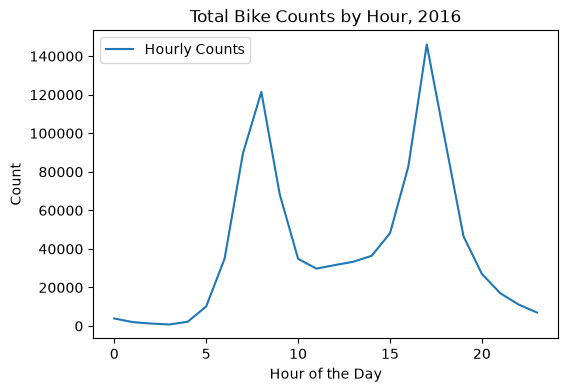

In [70]:
#import matplotlib.pyplot as plt

# Groups and sums by hour (0-23)
hourly_totals_2016 = df_2016.groupby('Hour')['Total (East + West) bicycle count'].sum()
print(hourly_totals_2016)

# Plots counts
plt.figure(figsize=(6, 4))
plt.plot(hourly_totals_2016.index,              # x-axis 
         hourly_totals_2016.values,             # y-axis
         label = 'Hourly Counts')               # label

# Structural annotations 
plt.title('Total Bike Counts by Hour, 2016')
plt.xlabel('Hour of the Day')
plt.ylabel('Count')
plt.legend()

plt.savefig('counts_by_hour.png')
plt.show()

Text(0, 0.5, 'Count')

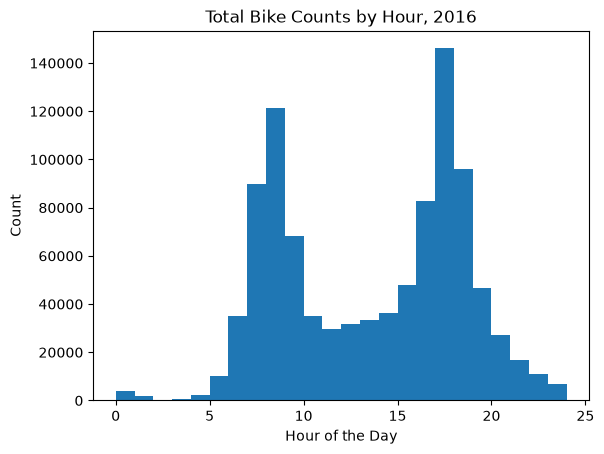

In [61]:
# Plots a histogram of the data
plt.hist(
    df_2016['Hour'], 
    bins=24, 
    range=(0, 24), 
    weights=df_2016['Total (East + West) bicycle count'])

# Structural annotations 
plt.title('Total Bike Counts by Hour, 2016')
plt.xlabel('Hour of the Day')
plt.ylabel('Count')

# 7. For the dataframe you created in 4, use python (and pandas) programming to computationally determine what is (on average) the busiest hour of the day. In a comment in the code write out the busiest hour (1pt)

In [ ]:
# Groups by hour and takes the average
hourly_avg_2016 = df_2016.groupby('Hour')['Total (East + West) bicycle count'].mean()

busiest_hour = hourly_avg_2016.idxmax()

print(busiest_hour, hourly_avg_2016.max())

# Using the 2016 subset, the busiest hour of the day on average is 17:00 with 366.03 bicycles.  

17 399.0327868852459


In [ ]:
#print(hourly_avg_2016.idxmax(), hourly_avg_2016.max())


17 399.0327868852459
